# Disease-Based Active Questioning System

This notebook demonstrates the disease-based active questioning approach for medical diagnosis.

## Overview

This system:
1. Predicts diseases directly from symptoms using ANN model
2. Asks questions to discriminate between SIMILAR DISEASES
3. Provides specific disease diagnosis when confidence >85%

## Key Differences from Department-Based Approach

| Aspect | Disease-Based | Department-Based |
|--------|---------------|------------------|
| Prediction Target | 577 diseases | 26 departments |
| Aggregation | Individual disease probabilities | SUM of diseases in same department |
| Questions Focus | Distinguish between similar diseases | Distinguish between departments |
| Clinical Goal | Specific disease diagnosis | Department referral |
| Confidence Threshold | Disease probability >85% | Department probability >85% |

---

## Setup and Imports

In [1]:
import sys
import os
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to path
BASE_DIR = Path.cwd().parent.parent
sys.path.insert(0, str(BASE_DIR))

from app_v2.services.ann_service import ANNService
from app_v2.services.active_questioning import ActiveQuestioningEngine

# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print(" Imports successful")
print(f" Project root: {BASE_DIR}")

 Imports successful
 Project root: /Users/dinhquanghien/Desktop/Report


## Load Models and Data

In [2]:
# File paths
MODEL_PATH = BASE_DIR / "building_ANN/models/pytorch/best_model.pth"
LABEL_ENCODER_PATH = BASE_DIR / "building_ANN/models/pytorch/label_encoder.pkl"
TRAIN_DATA_PATH = BASE_DIR / "building_ANN/data/processed/common/train.csv"
CONFUSION_MATRIX_PATH = BASE_DIR / "building_ANN/data/evaluation/most_confused_pairs.csv"
DEPT_MAP_PATH = BASE_DIR / "building_ANN/utils/department_map_577.json"

# Load department map (for display purposes only)
print(" Loading department map (for reference)...")
with open(DEPT_MAP_PATH, 'r', encoding='utf-8') as f:
    dept_map = json.load(f)

print(f" Loaded department map: {len(dept_map)} diseases mapped")

 Loading department map (for reference)...
 Loaded department map: 577 diseases mapped


In [3]:
# Initialize ANN Service WITHOUT department-based questioning
print(" Initializing ANN Service with disease-based questioning...")

ann_service = ANNService(
    model_path=str(MODEL_PATH),
    label_encoder_path=str(LABEL_ENCODER_PATH),
    train_data_path=str(TRAIN_DATA_PATH),
    confusion_matrix_path=str(CONFUSION_MATRIX_PATH) if CONFUSION_MATRIX_PATH.exists() else None,
    department_map=None  # Disable department-based questioning
)

print(" ANN Service initialized successfully")
print(f" Model: {ann_service.model.__class__.__name__}")
print(f" Diseases: {len(ann_service.label_encoder.classes_)}")
print(f" Symptoms: {len(ann_service.symptom_columns)}")
print(f" Disease questioning: Enabled")
print(f" Department questioning: {'Enabled' if ann_service.dept_questioning_engine else 'Disabled'}")

 Initializing ANN Service with disease-based questioning...
 ANN Service initialized successfully
 Model: ANNDiseaseClassifier
 Diseases: 577
 Symptoms: 377
 Disease questioning: Enabled
 Department questioning: Disabled


---
## Test Scenario: Patient with Neurological Symptoms

We'll simulate a patient presenting with symptoms commonly associated with neurological conditions.

**Important**: This is the SAME scenario as the department-based notebook for direct comparison.

In [4]:
# Define initial symptoms (SAME as department-based notebook)
initial_symptoms = [
    "đau đầu",
    "sốt cao",
    "buồn nôn",
    "mệt mỏi"
]

print(" Initial symptoms reported by patient:")
for i, symptom in enumerate(initial_symptoms, 1):
    print(f"   {i}. {symptom}")

 Initial symptoms reported by patient:
   1. đau đầu
   2. sốt cao
   3. buồn nôn
   4. mệt mỏi


---
## Step 1: Initial Disease Prediction (ANN Model)

In [5]:
# Get initial disease prediction
prediction = ann_service.predict_from_symptoms(initial_symptoms, top_k=15)

print(f" Top disease: {prediction.top_disease}")
print(f" Confidence: {prediction.top_confidence*100:.2f}% ({prediction.confidence_category})")
print(f" Needs questioning: {'YES' if prediction.needs_questioning else 'NO'}")
print(f"\n Top 15 Disease Predictions:")

# Create DataFrame for better display
predictions_df = pd.DataFrame([
    {
        'Rank': i,
        'Disease': disease,
        'Probability': f"{probability*100:.2f}%",
        'Department': dept_map.get(disease, 'Khám tổng quát')
    }
    for i, (disease, probability) in enumerate(prediction.top_k_predictions[:15], 1)
])

predictions_df

Unknown symptoms (will be ignored): ['sốt cao', 'mệt mỏi']


 Top disease: ngộ độc khí carbon monoxide
 Confidence: 39.25% (LOW)
 Needs questioning: YES

 Top 15 Disease Predictions:


,Rank,Disease,Probability,Department
0,1,ngộ độc khí carbon monoxide,39.25%,Khám tổng quát
1,2,đau đầu sau khi chọc dịch não tủy,14.04%,Thần kinh
2,3,viêm màng não,9.79%,Thần kinh
3,4,đau đầu do căng thẳng,8.26%,Khám tổng quát
4,5,chứng đau nửa đầu,4.94%,Thần kinh
5,6,bệnh Meniere,3.93%,Tai Mũi Họng
6,7,xuất huyết não,2.27%,Cấp cứu
7,8,phản ứng thuốc,2.12%,Khám tổng quát
8,9,viêm mê đạo,2.09%,Khám tổng quát
9,10,cơn đau dọc vị trí kịch phát lành tính (bppv),1.72%,Khám tổng quát


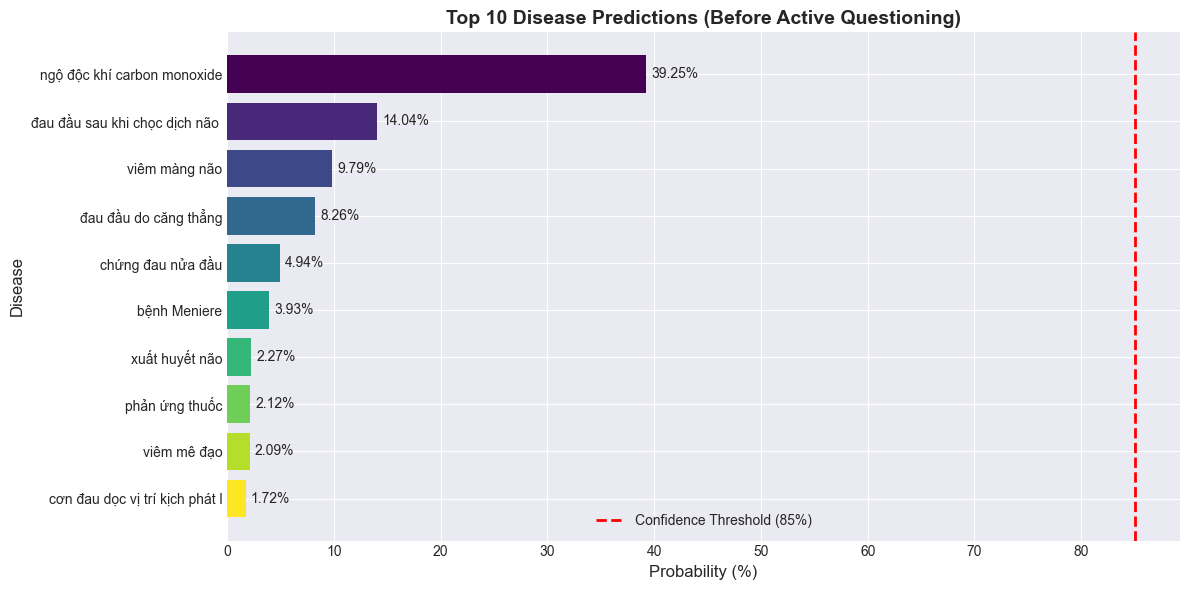

In [6]:
# Visualize disease predictions
fig, ax = plt.subplots(figsize=(12, 6))

diseases = [disease[:30] for disease, _ in prediction.top_k_predictions[:10]]  # Truncate long names
probs = [probability*100 for _, probability in prediction.top_k_predictions[:10]]

colors = plt.cm.viridis(np.linspace(0, 1, 10))
bars = ax.barh(diseases, probs, color=colors)

ax.set_xlabel('Probability (%)', fontsize=12)
ax.set_ylabel('Disease', fontsize=12)
ax.set_title('Top 10 Disease Predictions (Before Active Questioning)', fontsize=14, fontweight='bold')
ax.invert_yaxis()

# Add value labels
for bar, prob in zip(bars, probs):
    ax.text(prob + 0.5, bar.get_y() + bar.get_height()/2, 
            f'{prob:.2f}%', va='center', fontsize=10)

# Add threshold line
ax.axvline(x=85, color='red', linestyle='--', linewidth=2, label='Confidence Threshold (85%)')
ax.legend()

plt.tight_layout()
plt.show()

---
## Step 2: Active Questioning (Disease-Based)

Since no disease has >85% confidence, the system will ask questions to discriminate between similar diseases.

In [7]:
# Start disease-based questioning session
session_id = "disease_demo_session_001"

session, first_question = ann_service.start_questioning_session(
    session_id=session_id,
    initial_symptoms=initial_symptoms
)

print(f" Disease-Based Questioning Session:")
print(f"   Total disease hypotheses: {len(session.hypotheses)}")
print(f"   Initial confidence: {session.hypotheses[0].probability*100:.2f}%")
print(f"   Max questions: {session.max_questions}")

Unknown symptoms (will be ignored): ['sốt cao', 'mệt mỏi']


 Disease-Based Questioning Session:
   Total disease hypotheses: 10
   Initial confidence: 39.25%
   Max questions: 10


In [8]:
# Display top disease hypotheses
print(f"\n Top 10 Disease Hypotheses:")

disease_data = []
for i, hyp in enumerate(session.hypotheses[:10], 1):
    disease_data.append({
        'Rank': i,
        'Disease': hyp.disease_name,
        'Probability': f"{hyp.probability*100:.2f}%",
        'Department': dept_map.get(hyp.disease_name, 'Khám tổng quát')
    })

disease_df = pd.DataFrame(disease_data)
disease_df


 Top 10 Disease Hypotheses:


,Rank,Disease,Probability,Department
0,1,ngộ độc khí carbon monoxide,39.25%,Khám tổng quát
1,2,đau đầu sau khi chọc dịch não tủy,14.04%,Thần kinh
2,3,viêm màng não,9.79%,Thần kinh
3,4,đau đầu do căng thẳng,8.26%,Khám tổng quát
4,5,chứng đau nửa đầu,4.94%,Thần kinh
5,6,bệnh Meniere,3.93%,Tai Mũi Họng
6,7,xuất huyết não,2.27%,Cấp cứu
7,8,phản ứng thuốc,2.12%,Khám tổng quát
8,9,viêm mê đạo,2.09%,Khám tổng quát
9,10,cơn đau dọc vị trí kịch phát lành tính (bppv),1.72%,Khám tổng quát


In [9]:
# Display first question
if first_question:
    print(" First Question:")
    print(f"   Q: {first_question.question_text}")
    print(f"   Symptom: {first_question.symptom_name}")
    print(f"   Reason: {first_question.reason}")
    print(f"   Information gain: {first_question.information_gain:.4f}")
else:
    print(" No questions needed - confidence already high enough!")

 First Question:
   Q: Cho tôi hỏi, bạn có các triệu chứng trầm cảm không?
   Symptom: các triệu chứng trầm cảm hoặc loạn thần
   Reason: Để phân biệt giữa các bệnh có khả năng cao
   Information gain: 0.7692


---
## Step 3: Simulated Question Answering

We'll simulate answering questions to see how the disease probabilities update.

In [10]:
# Simulate answering questions
# For demonstration, we'll answer based on a predefined pattern
# You can modify these answers to see different outcomes

questions_log = []
current_question = first_question
question_num = 1

# You can modify these answers to see different outcomes
SIMULATED_ANSWERS = [
    True,   # Answer YES to question 1
    True,   # Answer YES to question 2
    True,   # Answer YES to question 3
    False,  # Answer NO to question 4
    True,   # Answer YES to question 5
]

print(" Simulating Question-Answer Flow:")
print("="*80)

while current_question and not session.is_complete and question_num <= len(SIMULATED_ANSWERS):
    # Simulate answer
    has_symptom = SIMULATED_ANSWERS[question_num - 1]
    answer_text = "CÓ" if has_symptom else "KHÔNG"
    
    print(f"\n Question {question_num}:")
    print(f"   Q: {current_question.question_text}")
    print(f"   Symptom: {current_question.symptom_name}")
    print(f"   Patient answer: {answer_text}")
    
    # Log question
    questions_log.append({
        'question_num': question_num,
        'symptom': current_question.symptom_name,
        'question_text': current_question.question_text,
        'answer': answer_text,
        'info_gain': current_question.information_gain
    })
    
    # Process answer
    session, next_question = ann_service.answer_question(
        session_id=session_id,
        symptom_name=current_question.symptom_name,
        has_symptom=has_symptom
    )
    
    # Show updated top 3 diseases
    print(f"\n    Updated Disease Probabilities:")
    for i, hyp in enumerate(session.hypotheses[:3], 1):
        dept = dept_map.get(hyp.disease_name, 'Khám tổng quát')
        print(f"      {i}. {hyp.disease_name}: {hyp.probability*100:.2f}% ({dept})")
    
    if session.is_complete:
        print(f"\n    Questioning complete!")
        #print(f"   Stop reason: {session.stop_reason}")
        break
    
    current_question = next_question
    question_num += 1

print("\n" + "="*80)
print(f" Total questions asked: {session.questions_asked}")

Unknown symptoms (will be ignored): ['sốt cao', 'mệt mỏi']


 Simulating Question-Answer Flow:

 Question 1:
   Q: Cho tôi hỏi, bạn có các triệu chứng trầm cảm không?
   Symptom: các triệu chứng trầm cảm hoặc loạn thần
   Patient answer: CÓ

    Updated Disease Probabilities:
      1. ngộ độc khí carbon monoxide: 98.89% (Khám tổng quát)
      2. xuất huyết não: 0.65% (Cấp cứu)
      3. tăng kali máu: 0.15% (Khám tổng quát)

    Questioning complete!

 Total questions asked: 1


In [11]:
# Display questions log
if questions_log:
    questions_df = pd.DataFrame(questions_log)
    print(" Questions Asked:")
    display(questions_df)

 Questions Asked:


,question_num,symptom,question_text,answer,info_gain
0,1,các triệu chứng trầm cảm hoặc loạn thần,"Cho tôi hỏi, bạn có các triệu chứng trầm cảm k...",CÓ,0.769231


---
## Step 4: Final Results

In [13]:
# Display final results
final_disease = session.final_diagnosis

print("="*80)
print(" FINAL DISEASE DIAGNOSIS")
print("="*80)

print(f"\n Disease: {final_disease.disease_name}")
print(f" Confidence: {final_disease.probability*100:.2f}%")
print(f" Department: {dept_map.get(final_disease.disease_name, 'Khám tổng quát')}")
print(f" Questions asked: {session.questions_asked}")
#print(f" Stop reason: {session.stop_reason}")

print(f"\n Confidence Improvement:")
print(f"   Initial: {session.hypotheses[0].probability*100:.2f}%")
print(f"   Final: {final_disease.probability*100:.2f}%")
print(f"   Gain: +{(final_disease.probability - session.hypotheses[0].probability)*100:.2f}%")

print("\n" + "="*80)

 FINAL DISEASE DIAGNOSIS

 Disease: ngộ độc khí carbon monoxide
 Confidence: 98.89%
 Department: Khám tổng quát
 Questions asked: 1

 Confidence Improvement:
   Initial: 98.89%
   Final: 98.89%
   Gain: +0.00%



In [14]:
# Show top 10 diseases after questioning
print(f" Top 10 Diseases (After Active Questioning):")
print("="*80)

final_diseases = []
for i, hyp in enumerate(session.hypotheses[:10], 1):
    final_diseases.append({
        'Rank': i,
        'Disease': hyp.disease_name,
        'Probability': f"{hyp.probability*100:.2f}%",
        'Department': dept_map.get(hyp.disease_name, 'Khám tổng quát')
    })

final_diseases_df = pd.DataFrame(final_diseases)
final_diseases_df

 Top 10 Diseases (After Active Questioning):


,Rank,Disease,Probability,Department
0,1,ngộ độc khí carbon monoxide,98.89%,Khám tổng quát
1,2,xuất huyết não,0.65%,Cấp cứu
2,3,tăng kali máu,0.15%,Khám tổng quát
3,4,xuất huyết nội sọ,0.08%,Khám tổng quát
4,5,hạ đường huyết,0.05%,Nội tiết
5,6,xuất huyết dưới màng cứng,0.04%,Khám tổng quát
6,7,nhiễm toan ceton do đái tháo đường,0.03%,Nội tiết
7,8,tăng huyết áp ác tính,0.02%,Tim mạch
8,9,não úng thủy,0.02%,Thần kinh
9,10,viêm màng não,0.01%,Thần kinh


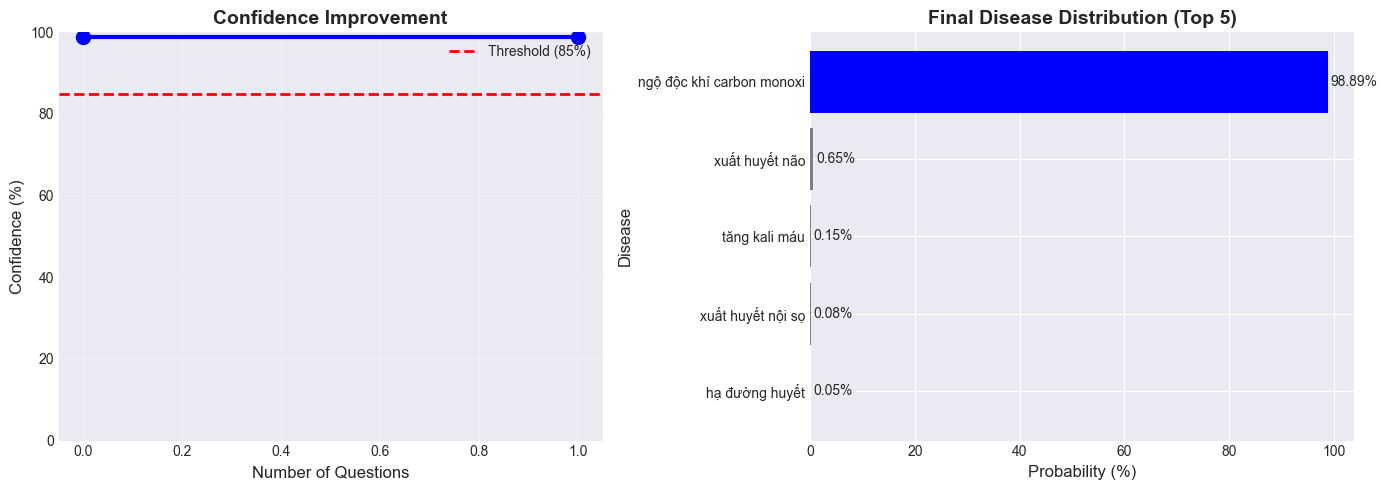

In [15]:
# Visualize confidence improvement and final distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: Confidence progression
confidences = [session.hypotheses[0].probability * 100]
# Note: We'd need to track intermediate confidences during questioning for full progression
# For now, we'll show initial vs final
confidences.append(final_disease.probability * 100)

ax1.plot([0, session.questions_asked], confidences, marker='o', linewidth=3, markersize=10, color='blue')
ax1.axhline(y=85, color='red', linestyle='--', linewidth=2, label='Threshold (85%)')
ax1.set_xlabel('Number of Questions', fontsize=12)
ax1.set_ylabel('Confidence (%)', fontsize=12)
ax1.set_title('Confidence Improvement', fontsize=14, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.set_ylim(0, 100)

# Right: Final disease distribution
top_5_diseases = [hyp.disease_name[:25] for hyp in session.hypotheses[:5]]
top_5_probs = [hyp.probability*100 for hyp in session.hypotheses[:5]]

colors_final = ['blue' if hyp.disease_name == final_disease.disease_name else 'gray' 
                for hyp in session.hypotheses[:5]]
bars = ax2.barh(top_5_diseases, top_5_probs, color=colors_final)
ax2.set_xlabel('Probability (%)', fontsize=12)
ax2.set_ylabel('Disease', fontsize=12)
ax2.set_title('Final Disease Distribution (Top 5)', fontsize=14, fontweight='bold')
ax2.invert_yaxis()

# Add value labels
for bar, prob in zip(bars, top_5_probs):
    ax2.text(prob + 0.5, bar.get_y() + bar.get_height()/2, 
            f'{prob:.2f}%', va='center', fontsize=10)

plt.tight_layout()
plt.show()